# exohab quickstart

This notebook walks through the main features of **exohab**:

1. Habitability metrics for single planets
2. Loading live data from the NASA Exoplanet Archive
3. Monte Carlo uncertainty for one planet
4. Monte Carlo uncertainty for the whole catalogue
5. Plots
6. Machine-learning features

Requirements: `pip install "exohab[all]"`. Section 2 onwards needs an internet
connection the first time; after that the data is cached in `~/.exohab/cache`.

*The archive is updated continuously, so your numbers may differ slightly from
the saved outputs below.*

In [1]:
# Optional: only needed behind a corporate proxy or antivirus HTTPS scanning that
# causes "SSL: CERTIFICATE_VERIFY_FAILED". It uses your operating system's
# certificate store (pip install truststore); it does not disable verification.
try:
    import truststore
    truststore.inject_into_ssl()
except ImportError:
    pass

In [2]:
import matplotlib.pyplot as plt
import pandas as pd

import exohab as eh

pd.set_option("display.precision", 3)
print("exohab", eh.__version__)

exohab 0.2.0


## 1. Habitability metrics for single planets

The **two-parameter ESI** (Planetary Habitability Laboratory) needs only radius
(Earth radii) and stellar flux (Earth = 1). The **four-parameter ESI**
(Schulze-Makuch et al. 2011) uses radius, bulk density and escape velocity
(Earth units) plus mean surface temperature (K), and is split into an
*interior* and a *surface* part.

In [3]:
print("Earth      2p ESI:", eh.compute_esi_2p(radius=1.0, flux=1.0))
print("Mars       2p ESI:", round(eh.compute_esi_2p(radius=0.532, flux=0.431), 3))
print("Proxima b  2p ESI:", round(eh.compute_esi_2p(radius=1.12, flux=0.7005), 3))

mars = eh.compute_esi_4p(radius=0.53, density=0.71, escape_velocity=0.45, surface_temp=240.0)
print(f"Mars 4p ESI: interior={mars.interior:.2f} surface={mars.surface:.2f} global={mars.esi:.2f}")

# Similarity to another body, e.g. the Mars Similarity Index (Kashyap Jagadeesh et al. 2017)
print("Earth on the Mars scale:", round(eh.compute_similarity(1.0, 1.0, 1.0, 288.0, reference="mars").esi, 3))

Earth      2p ESI: 1.0
Mars       2p ESI: 0.645
Proxima b  2p ESI: 0.869
Mars 4p ESI: interior=0.82 surface=0.65 global=0.73
Earth on the Mars scale: 0.683


## 2. Live data from the NASA Exoplanet Archive

`load_nasa_exoplanets` queries the `pscomppars` table (one row per confirmed
planet) and adds derived columns: `density_eu`, `escape_velocity_eu`, `esi_2p`,
`esi_4p_interior`, `esi_4p_surface` and `esi_4p`.

Catalogues list *equilibrium* temperature, not surface temperature. Here we ask
exohab to convert it with the Kashyap Jagadeesh (2017) relation
`T_s = 9.650 + 1.096 T_eq`. That relation is only meaningful for rocky planets
with an atmosphere.

In [4]:
df = eh.load_nasa_exoplanets(surface_temp_method="kashyap2017")
print(len(df), "planets |", df.attrs["esi_4p_temperature"])

cols = ["pl_name", "pl_rade", "pl_bmasse", "pl_insol", "pl_eqt", "surface_temp_est", "esi_2p", "esi_4p"]
df.nlargest(10, "esi_4p")[cols]

6470 planets | surface temperature estimated from 'pl_eqt' (kashyap2017)


,pl_name,pl_rade,pl_bmasse,pl_insol,pl_eqt,surface_temp_est,esi_2p,esi_4p
2451,Wolf 1069 b,1.080,1.260,0.652,250.10,283.760,0.849,0.977
1634,TRAPPIST-1 e,0.920,0.692,0.646,249.70,283.321,0.845,0.954
3831,Kepler-1649 c,1.060,1.200,0.750,234.00,266.114,0.897,0.935
4730,Teegarden's Star b,1.050,1.160,1.080,277.00,313.242,0.968,0.934
5124,GJ 1061 d,1.160,1.670,0.600,242.03,274.915,0.816,0.933
2307,TOI-700 d,1.145,1.580,0.850,268.80,304.255,0.925,0.932
1237,GJ 1002 b,1.030,1.080,0.670,230.90,262.716,0.860,0.931
2428,TOI-700 e,0.919,0.718,1.270,272.90,308.748,0.911,0.926
6439,Kepler-442 b,1.340,2.360,0.660,241.00,273.786,0.822,0.916
1922,GJ 3378 b,1.320,2.300,0.910,272.00,307.762,0.897,0.910


## 3. Monte Carlo uncertainty for one planet

Measurements come with (often asymmetric) error bars. exohab samples each
input from a split normal distribution and returns the ESI distribution.
Passing `mass` derives density and escape velocity for each draw, so their
correlation is kept. The values below are read straight from the archive row,
including its `err1`/`err2` columns.

TRAPPIST-1 e: ESI median 0.954, 68% interval 0.944-0.963, 95% interval 0.934-0.972
interior median: 0.956 | surface median: 0.952


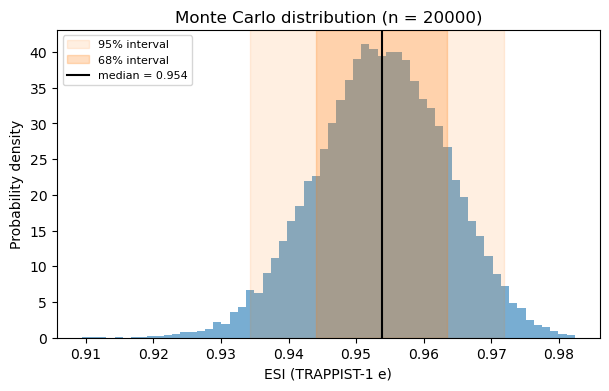

In [5]:
p = df.set_index("pl_name").loc["TRAPPIST-1 e"]

ts = eh.estimate_surface_temp(p.pl_eqt)          # equilibrium -> surface temperature
ts_err = 1.096 * p.pl_eqterr1                     # the linear relation scales the error too

mc = eh.compute_esi_mc(
    radius=(p.pl_rade, p.pl_radeerr1, p.pl_radeerr2),
    mass=(p.pl_bmasse, p.pl_bmasseerr1, p.pl_bmasseerr2),
    surface_temp=(ts, ts_err),
    n_samples=20_000,
    seed=42,
)
print(f"TRAPPIST-1 e: ESI median {mc.median:.3f}, 68% interval {mc.ci68[0]:.3f}-{mc.ci68[1]:.3f}, "
      f"95% interval {mc.ci95[0]:.3f}-{mc.ci95[1]:.3f}")
print("interior median:", round(mc.components["interior"].median, 3),
      "| surface median:", round(mc.components["surface"].median, 3))

eh.plot_mc_distribution(mc, label="ESI (TRAPPIST-1 e)")
plt.show()

Large or lopsided error bars can shift the distribution a lot. Kepler-442 b's
flux is 0.66 +0.23/-0.41. With `truncate=True`, negative flux draws are redrawn
rather than discarded, so all 20,000 samples are kept.

In [6]:
k = df.set_index("pl_name").loc["Kepler-442 b"]
mc2 = eh.compute_esi_2p_mc(
    radius=(k.pl_rade, k.pl_radeerr1, k.pl_radeerr2),
    flux=(k.pl_insol, k.pl_insolerr1, k.pl_insolerr2),
    n_samples=20_000, seed=42, truncate=True,
)
print(f"point ESI {k.esi_2p:.3f} | MC median {mc2.median:.3f} "
      f"(68%: {mc2.ci68[0]:.3f}-{mc2.ci68[1]:.3f}), valid samples: {mc2.n_valid}")

point ESI 0.822 | MC median 0.784 (68%: 0.585-0.883), valid samples: 20000


## 4. Monte Carlo uncertainty for the whole catalogue

`compute_esi_mc_catalog` runs the same propagation for every planet, using
the archive's error columns. Planets with missing error bars are flagged
(`errors_complete = False`), because their intervals understate the real
uncertainty.

In [7]:
unc = eh.compute_esi_mc_catalog(df, method="2p", n_samples=2000, seed=0)
ranked = df[["pl_name", "esi_2p"]].join(unc)
ranked.nlargest(10, "esi_2p_mc_median")[
    ["pl_name", "esi_2p", "esi_2p_mc_median", "esi_2p_mc_ci68_low",
     "esi_2p_mc_ci68_high", "esi_2p_mc_errors_complete"]
]

,pl_name,esi_2p,esi_2p_mc_median,esi_2p_mc_ci68_low,esi_2p_mc_ci68_high,esi_2p_mc_errors_complete
4730,Teegarden's Star b,0.968,0.966,0.946,0.980,False
2307,TOI-700 d,0.925,0.921,0.887,0.944,True
2428,TOI-700 e,0.911,0.915,0.879,0.950,True
1901,TRAPPIST-1 d,0.908,0.908,0.900,0.914,True
1922,GJ 3378 b,0.897,0.896,0.881,0.902,False
6465,LP 890-9 c,0.885,0.882,0.869,0.894,True
759,Ross 128 b,0.881,0.881,0.881,0.881,False
3535,K2-72 e,0.890,0.880,0.839,0.917,True
5125,GJ 1061 c,0.867,0.865,0.824,0.910,False
1237,GJ 1002 b,0.860,0.860,0.840,0.880,False


## 5. Plots

**Interior vs. surface ESI.** The dashed lines mark the 0.8 "Earth-like"
threshold; the dotted curves are lines of constant global ESI.

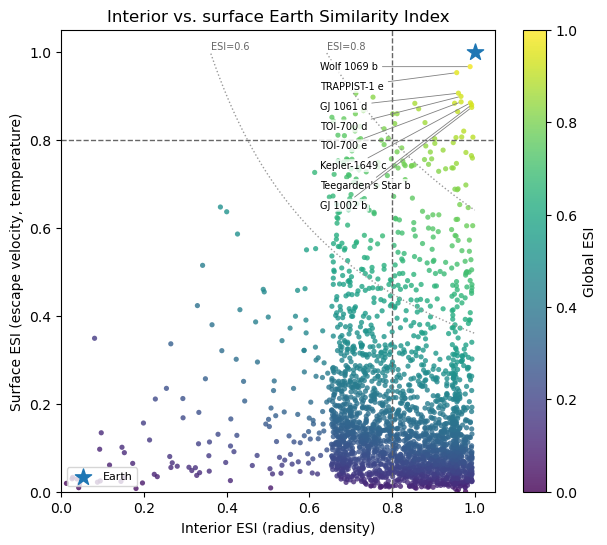

In [8]:
eh.plot_esi_scatter(df[df.pl_rade < 2.5], top_n=8)
plt.show()

**Habitable zone.** Stellar temperature vs. insolation, with the Kopparapu et
al. (2014) conservative (dark) and optimistic (light) habitable zones. The
fits are valid for 2600–7200 K.

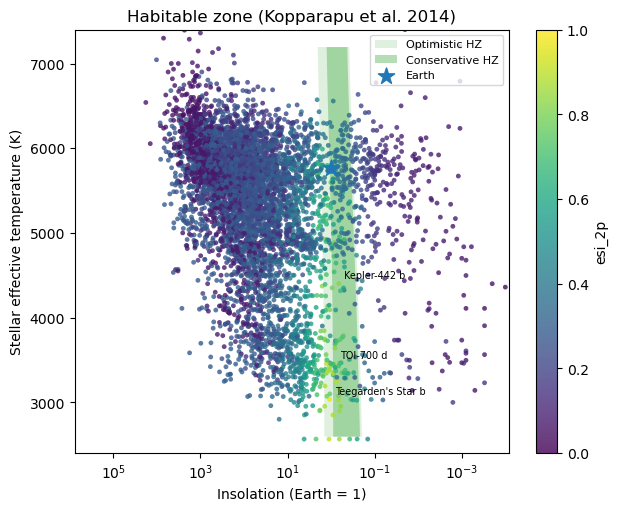

In [9]:
eh.plot_habitable_zone(df, color_col="esi_2p",
                       labels=["Kepler-442 b", "TOI-700 d", "Teegarden's Star b"])
plt.show()

## 6. Machine-learning features

`HabitabilityFeatureTransformer` is a scikit-learn transformer. It turns raw
archive columns into 15 habitability features, and can be used inside a
`Pipeline`.

In [ ]:
features = eh.HabitabilityFeatureTransformer(surface_temp_method="kashyap2017")
X = features.fit_transform(df)
print(X.shape)
print("planets inside the conservative habitable zone:", int(X["in_conservative_hz"].sum()))
X.describe().T[["count", "mean", "min", "max"]]

(6470, 15)
planets inside the conservative habitable zone: 185


,count,mean,min,max
density_eu,6397.0,3.054,5.487e-03,7141.442
escape_velocity_eu,6396.0,3.752,2.398e-01,102.254
esi_2p,5835.0,0.253,2.394e-02,0.968
esi_4p_interior,6396.0,0.580,1.221e-02,0.996
esi_4p_surface,5867.0,0.191,3.316e-04,0.966
esi_4p,5867.0,0.294,1.104e-02,0.977
esi_interior_surface_ratio,5867.0,9.999,1.136e-01,2040.443
hz_seff_inner,6080.0,1.064,9.135e-01,1.294
hz_seff_outer,6080.0,0.331,2.233e-01,0.435
hz_seff_inner_optimistic,6080.0,1.708,1.465e+00,2.075


## Notes

- ESI measures similarity to Earth. It is **not** a probability of life.
- `pl_bmasse` may be a minimum mass (M sin i) for radial-velocity planets.
- Every formula used is cited in its function's docstring and in the README.

*This research has made use of the NASA Exoplanet Archive, which is operated by
the California Institute of Technology, under contract with the National
Aeronautics and Space Administration under the Exoplanet Exploration Program.*